In [ ]:
!nvidia-smi

Mon Sep 14 15:32:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


In [ ]:
# Pip install method (recommended)

!pip install ultralytics

import ultralytics
ultralytics.checks()

Ultralytics 8.4.152 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 47.4/112.6 GB disk)


In [ ]:
from ultralytics import YOLO

from IPython.display import display, Image

In [ ]:
# 登入Roboflow's universe 選取 project's dataset

In [ ]:
!mkdir -p {HOME}/datasets
%cd {HOME}/datasets

!pip install roboflow

import os
from roboflow import Roboflow

api_key = os.getenv("ROBOFLOW_API_KEY")
if not api_key:
    raise RuntimeError("Set ROBOFLOW_API_KEY before running this cell.")

rf = Roboflow(api_key=api_key)
project = rf.workspace("roboflow-100").project("vehicles-q0x2v")
version = project.version(2)
dataset = version.download("yolov11")


/content/datasets
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.8/302.8 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 56.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 128.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.4 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to vehicles-2 in yolov11:: 100%|██████████| 8128/8128 [00:01<00:00, 7102.25it/s]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

DRIVE_DIR = "/content/drive/MyDrive/YOLO11 Vehicle Detection｜Model Training Demo"

os.makedirs(DRIVE_DIR, exist_ok=True)

print(DRIVE_DIR)

/content/drive/MyDrive/YOLO11 Vehicle Detection｜Model Training Demo


## Custom Training

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    project=DRIVE_DIR,
    name="train_50e",
    exist_ok=True
    )

Ultralytics 8.4.152 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/vehicles-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_50e, nbs=64, nms=None, opset=None

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7934c8f63c40>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,  

In [ ]:
!ls "{DRIVE_DIR}/train_50e"


ls: cannot access 'runs/detect/train/': No such file or directory


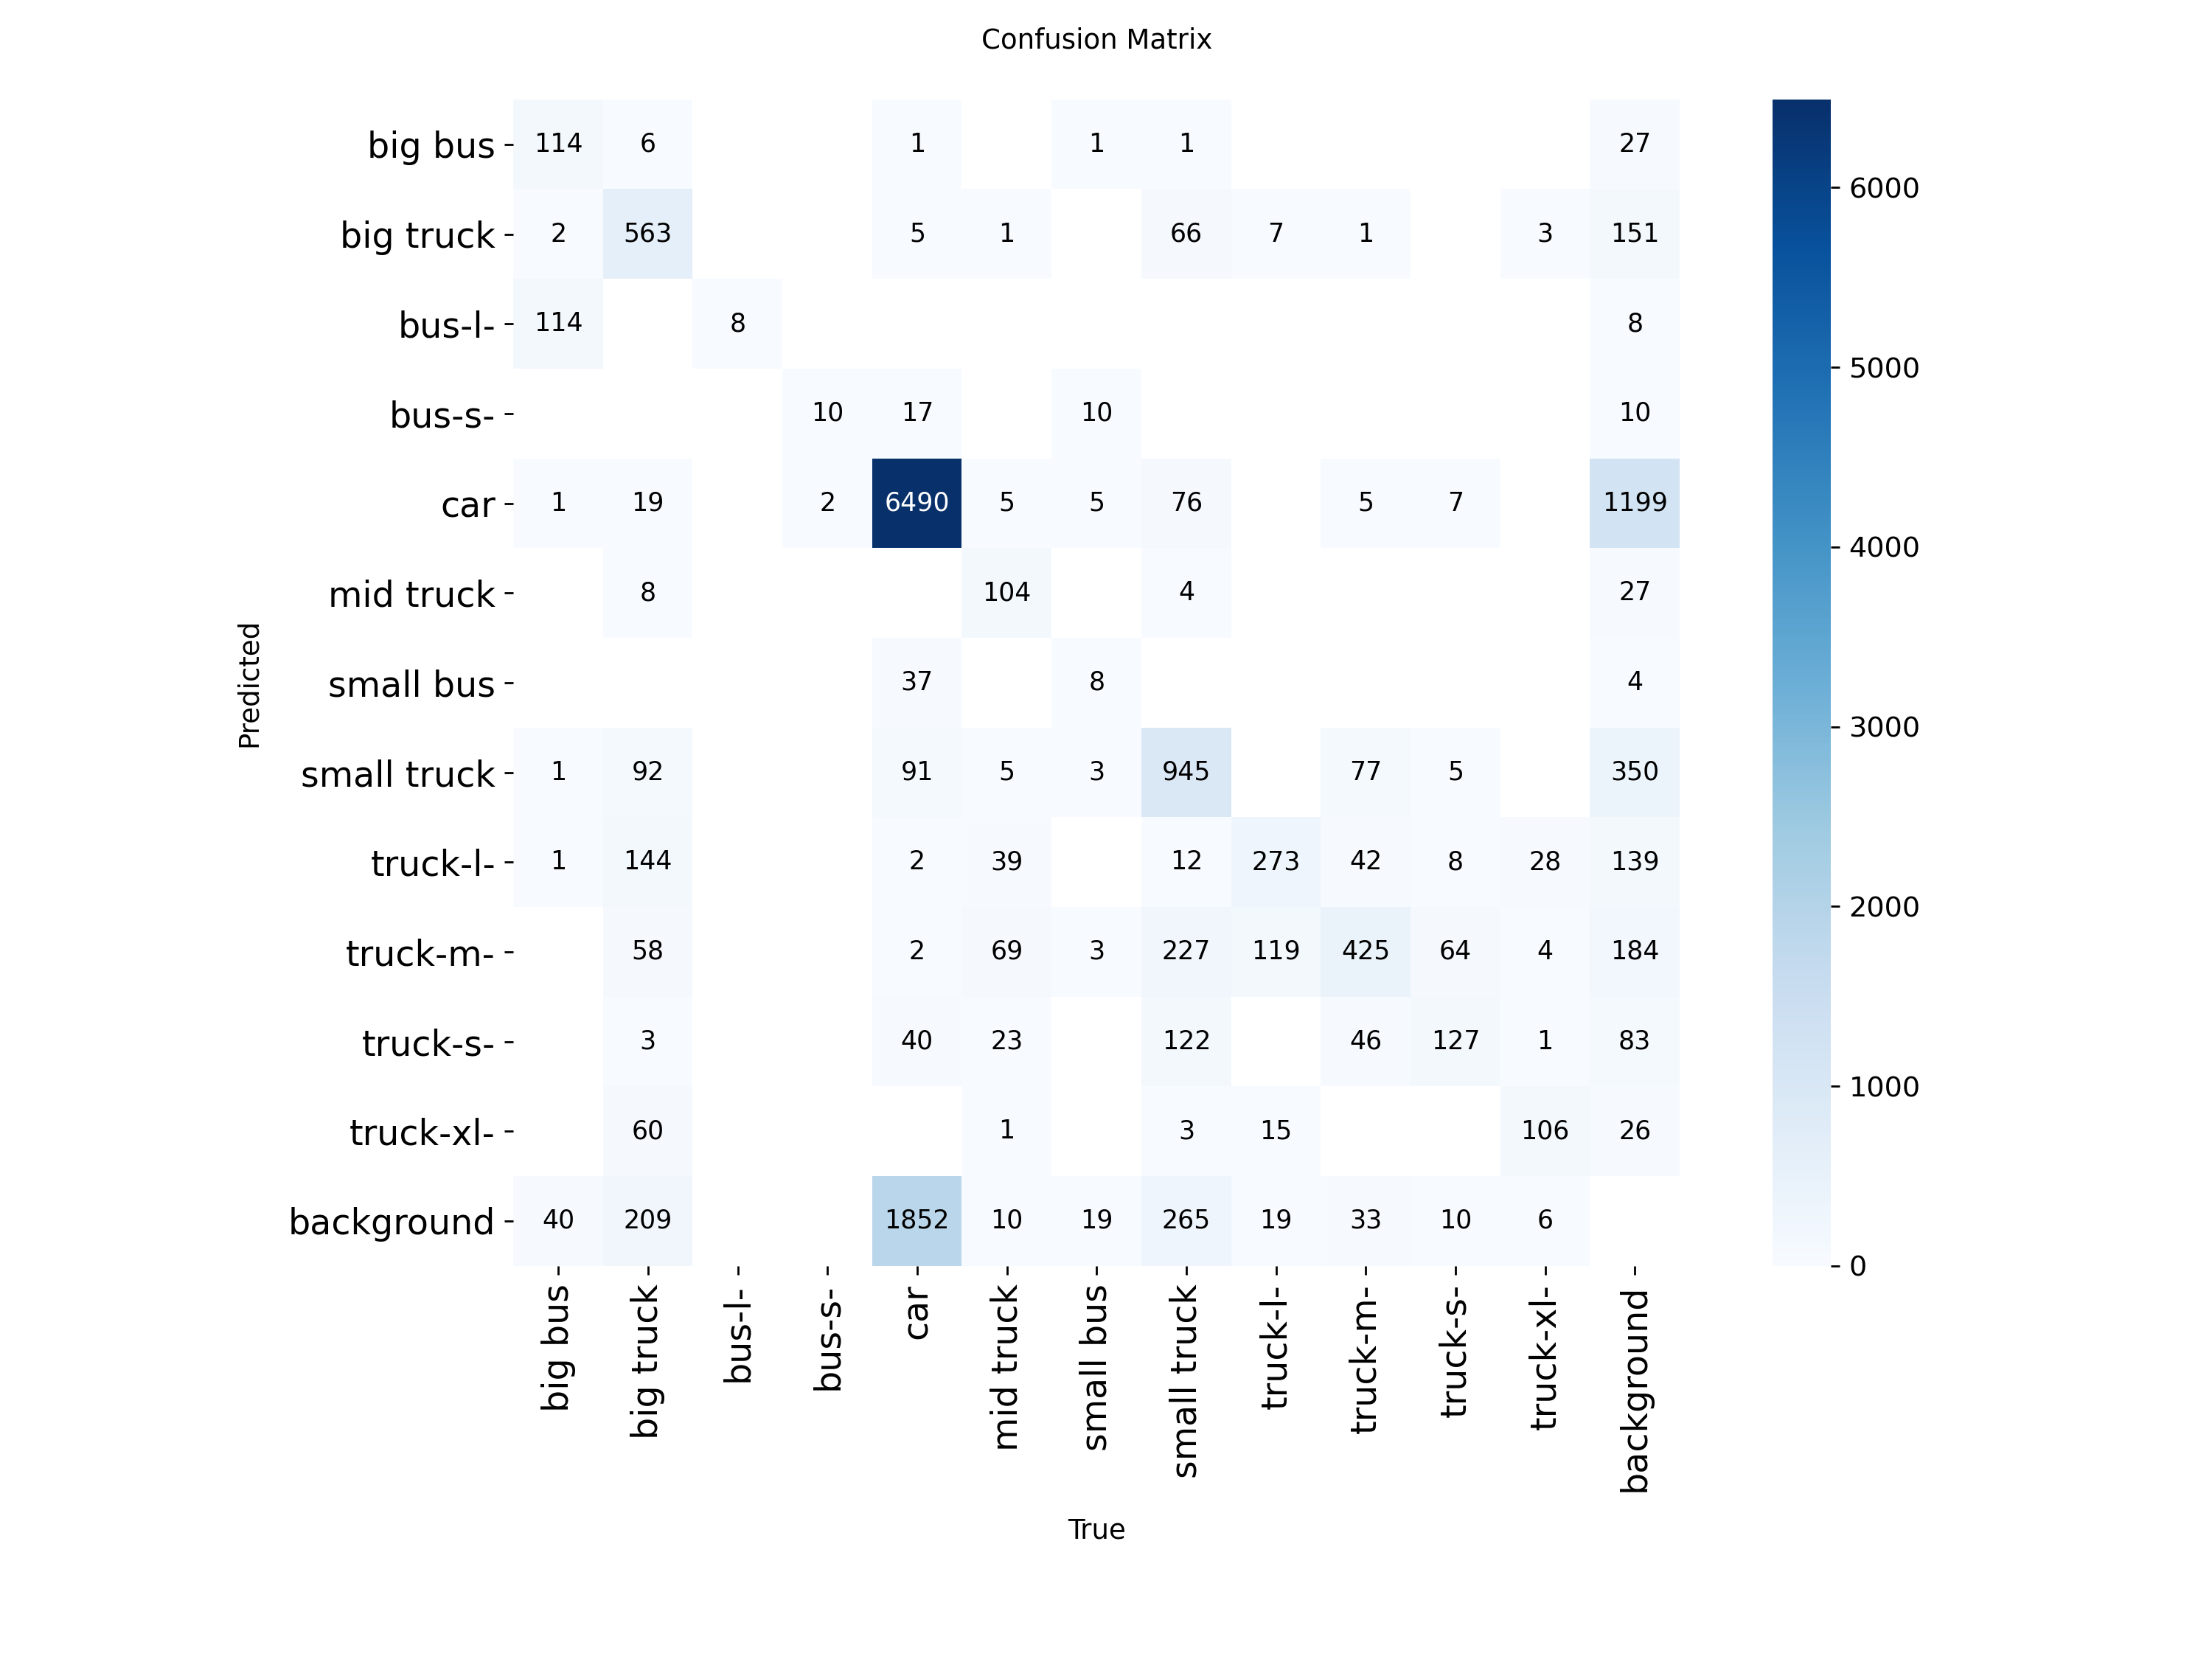

In [ ]:
from IPython.display import Image, display

display(
    Image(
        filename=f"{DRIVE_DIR}/train_50e/confusion_matrix.png",
        width=700
    )
)

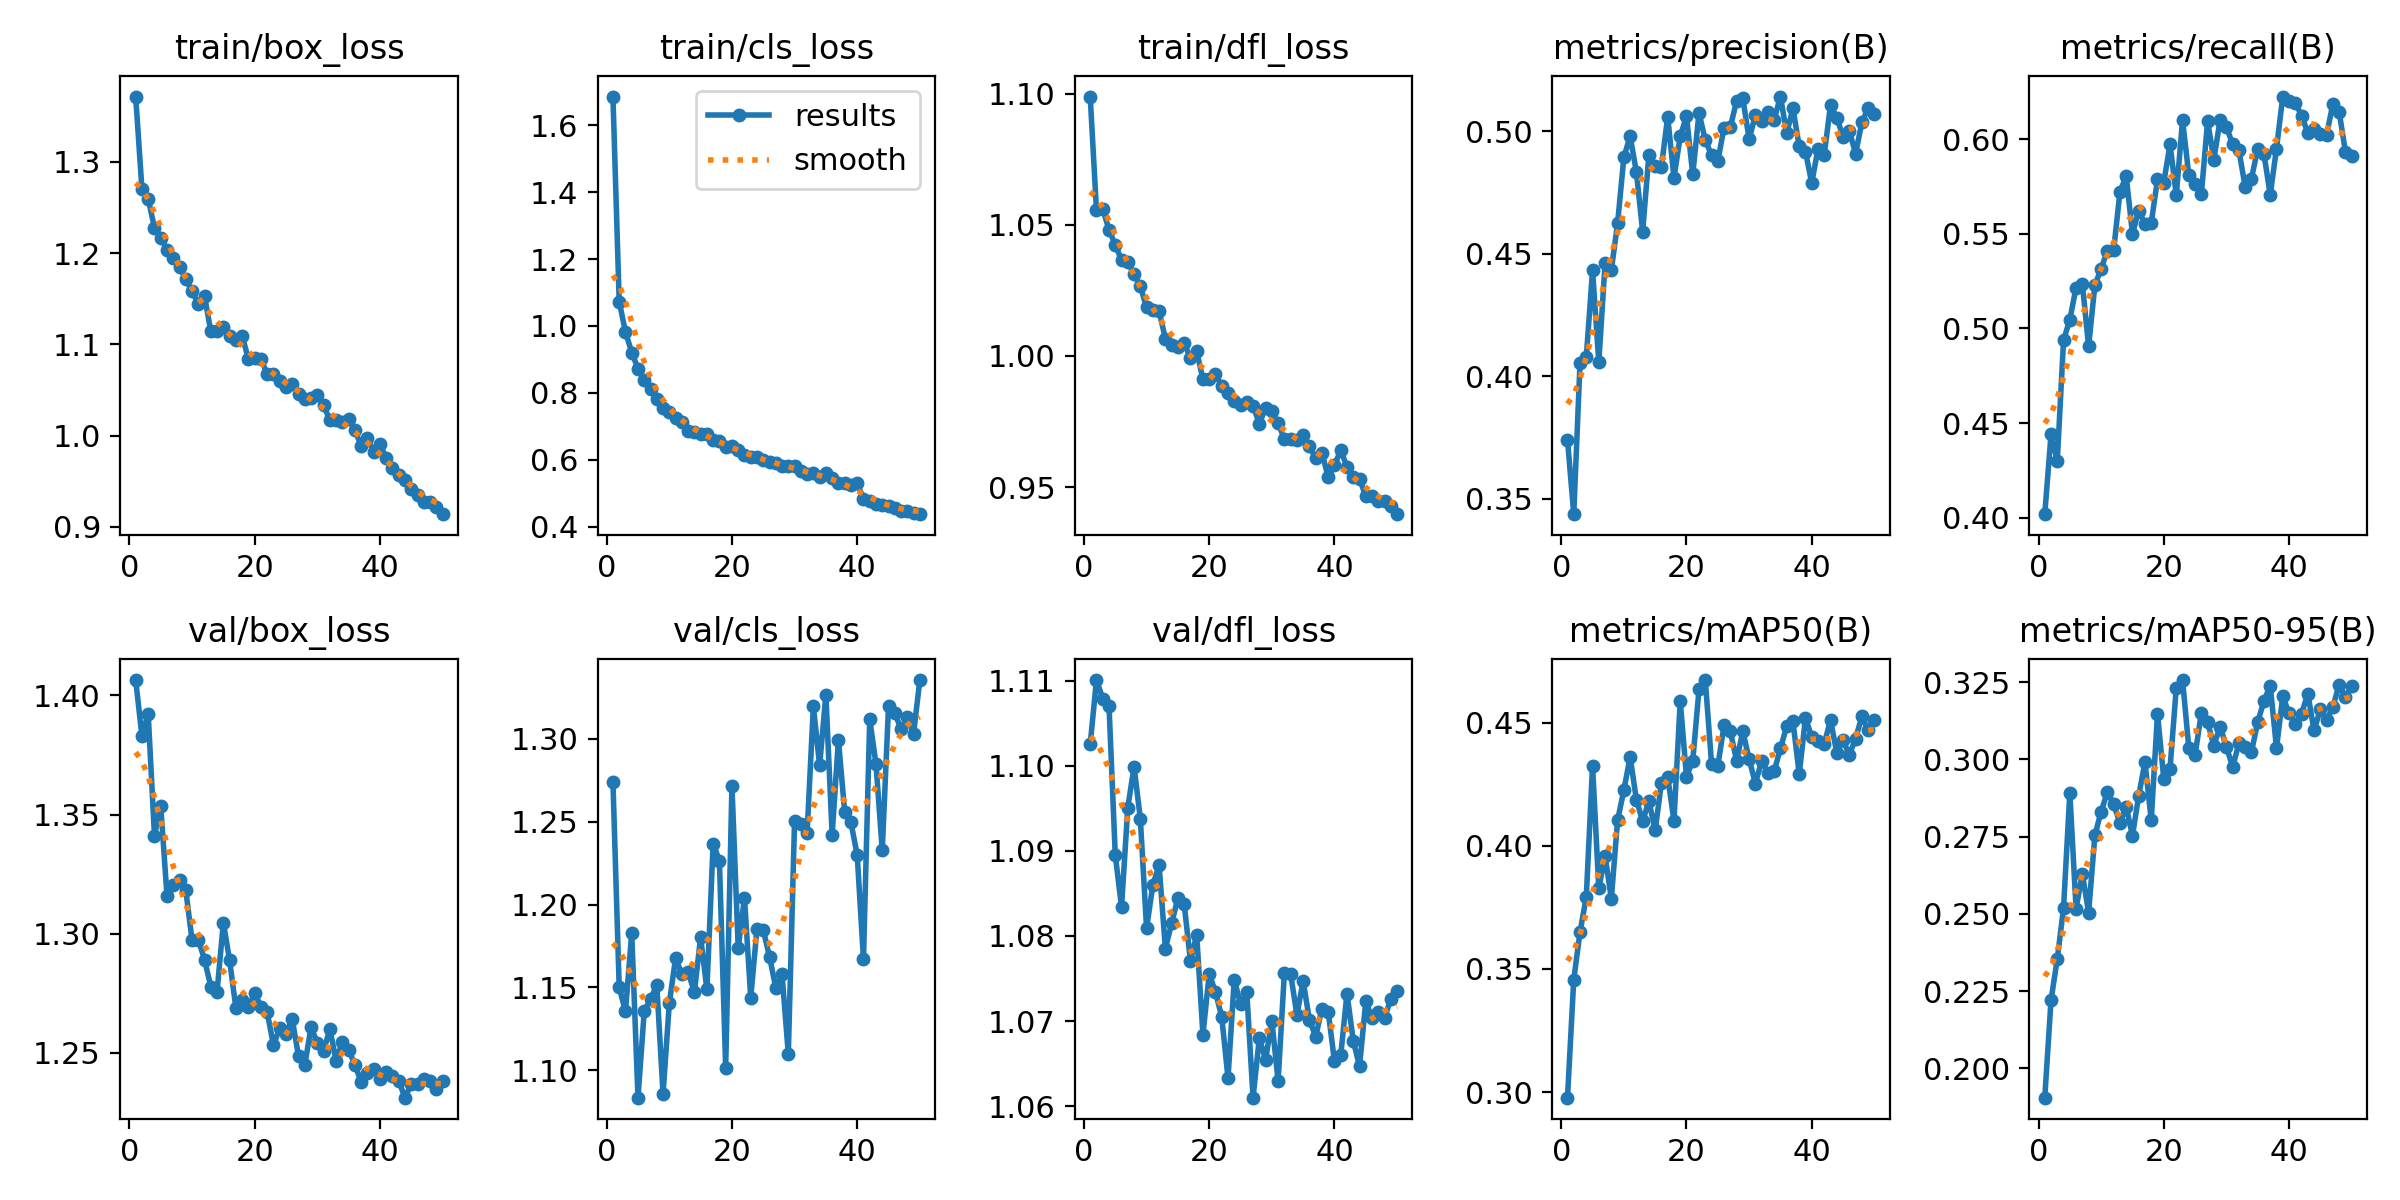

In [ ]:
display(
    Image(
        filename=f"{DRIVE_DIR}/train_50e/results.png",
        width=1300
    )
)

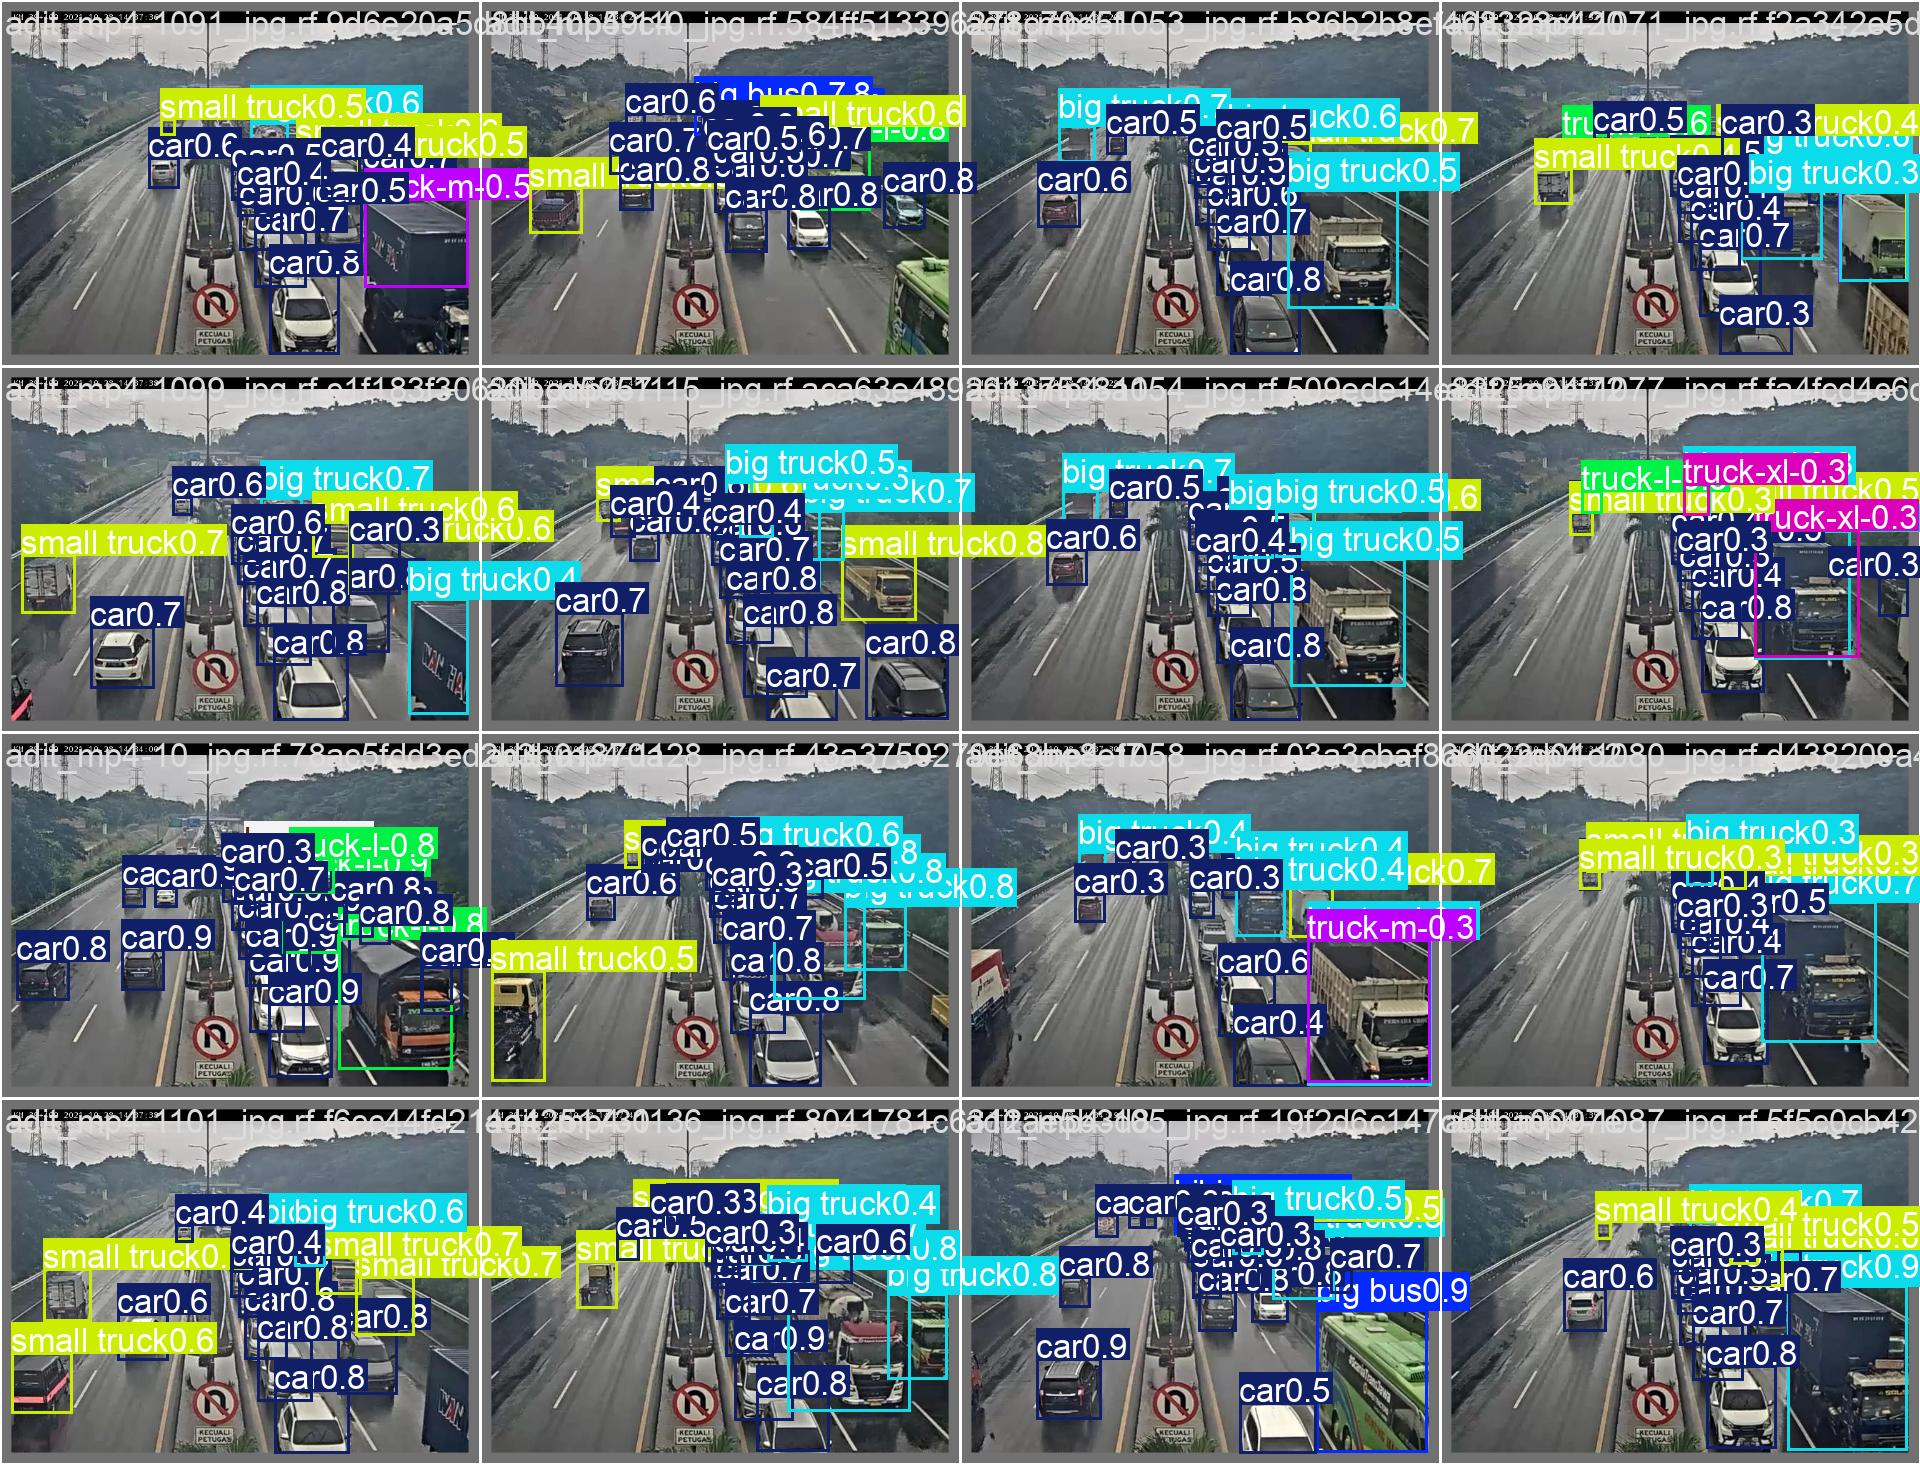

In [ ]:
display(
    Image(
        filename=f"{DRIVE_DIR}/train_50e/val_batch1_pred.jpg",
        width=900
    )
)


===== results.png =====


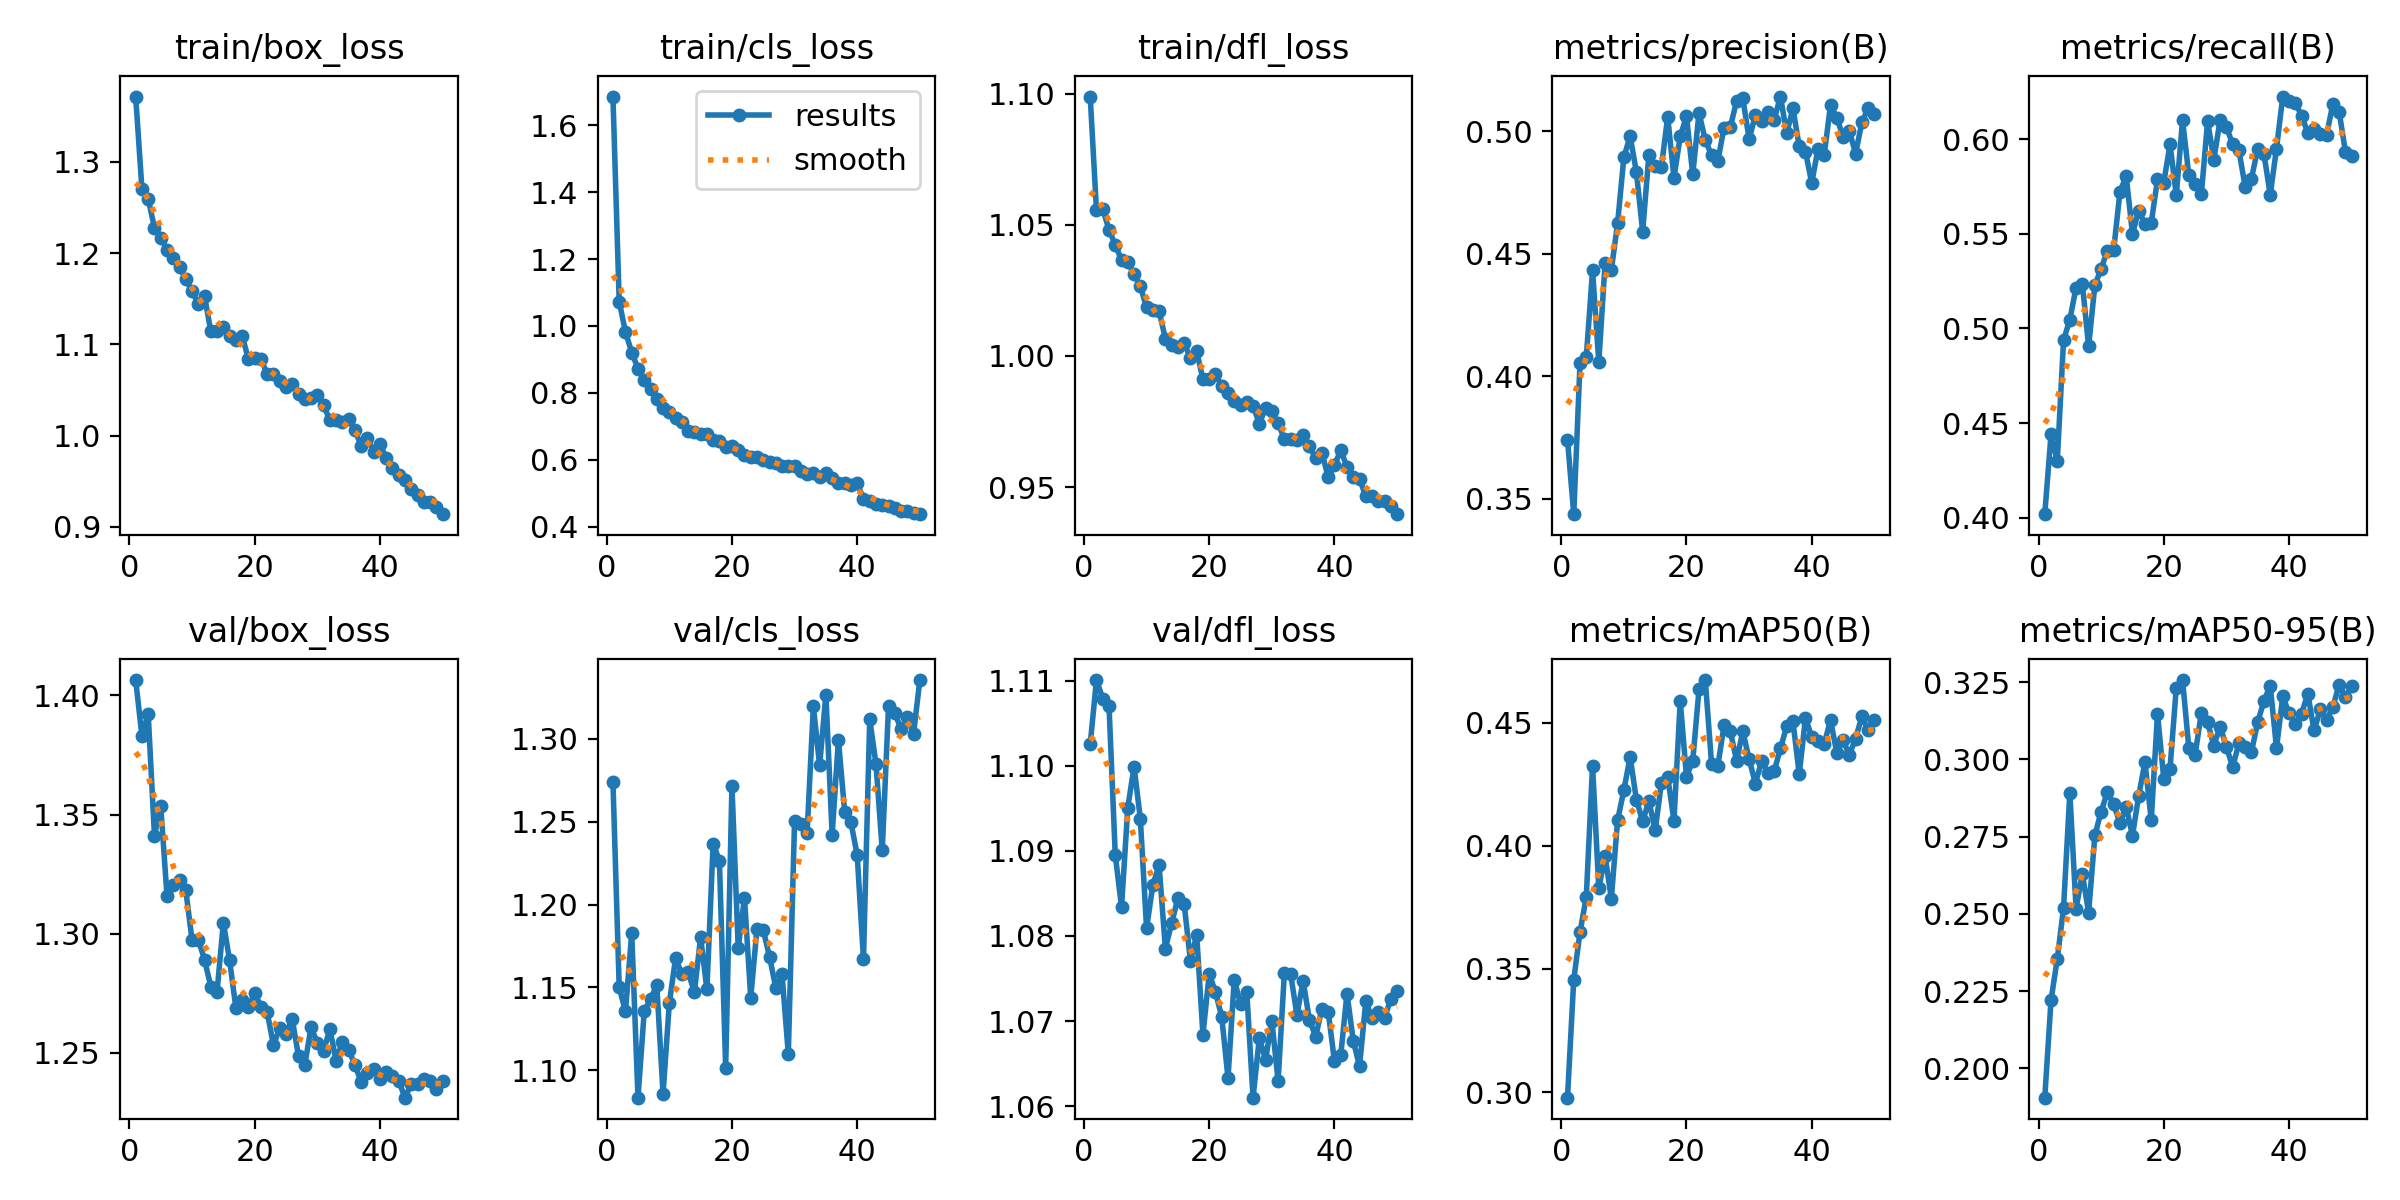


===== confusion_matrix.png =====


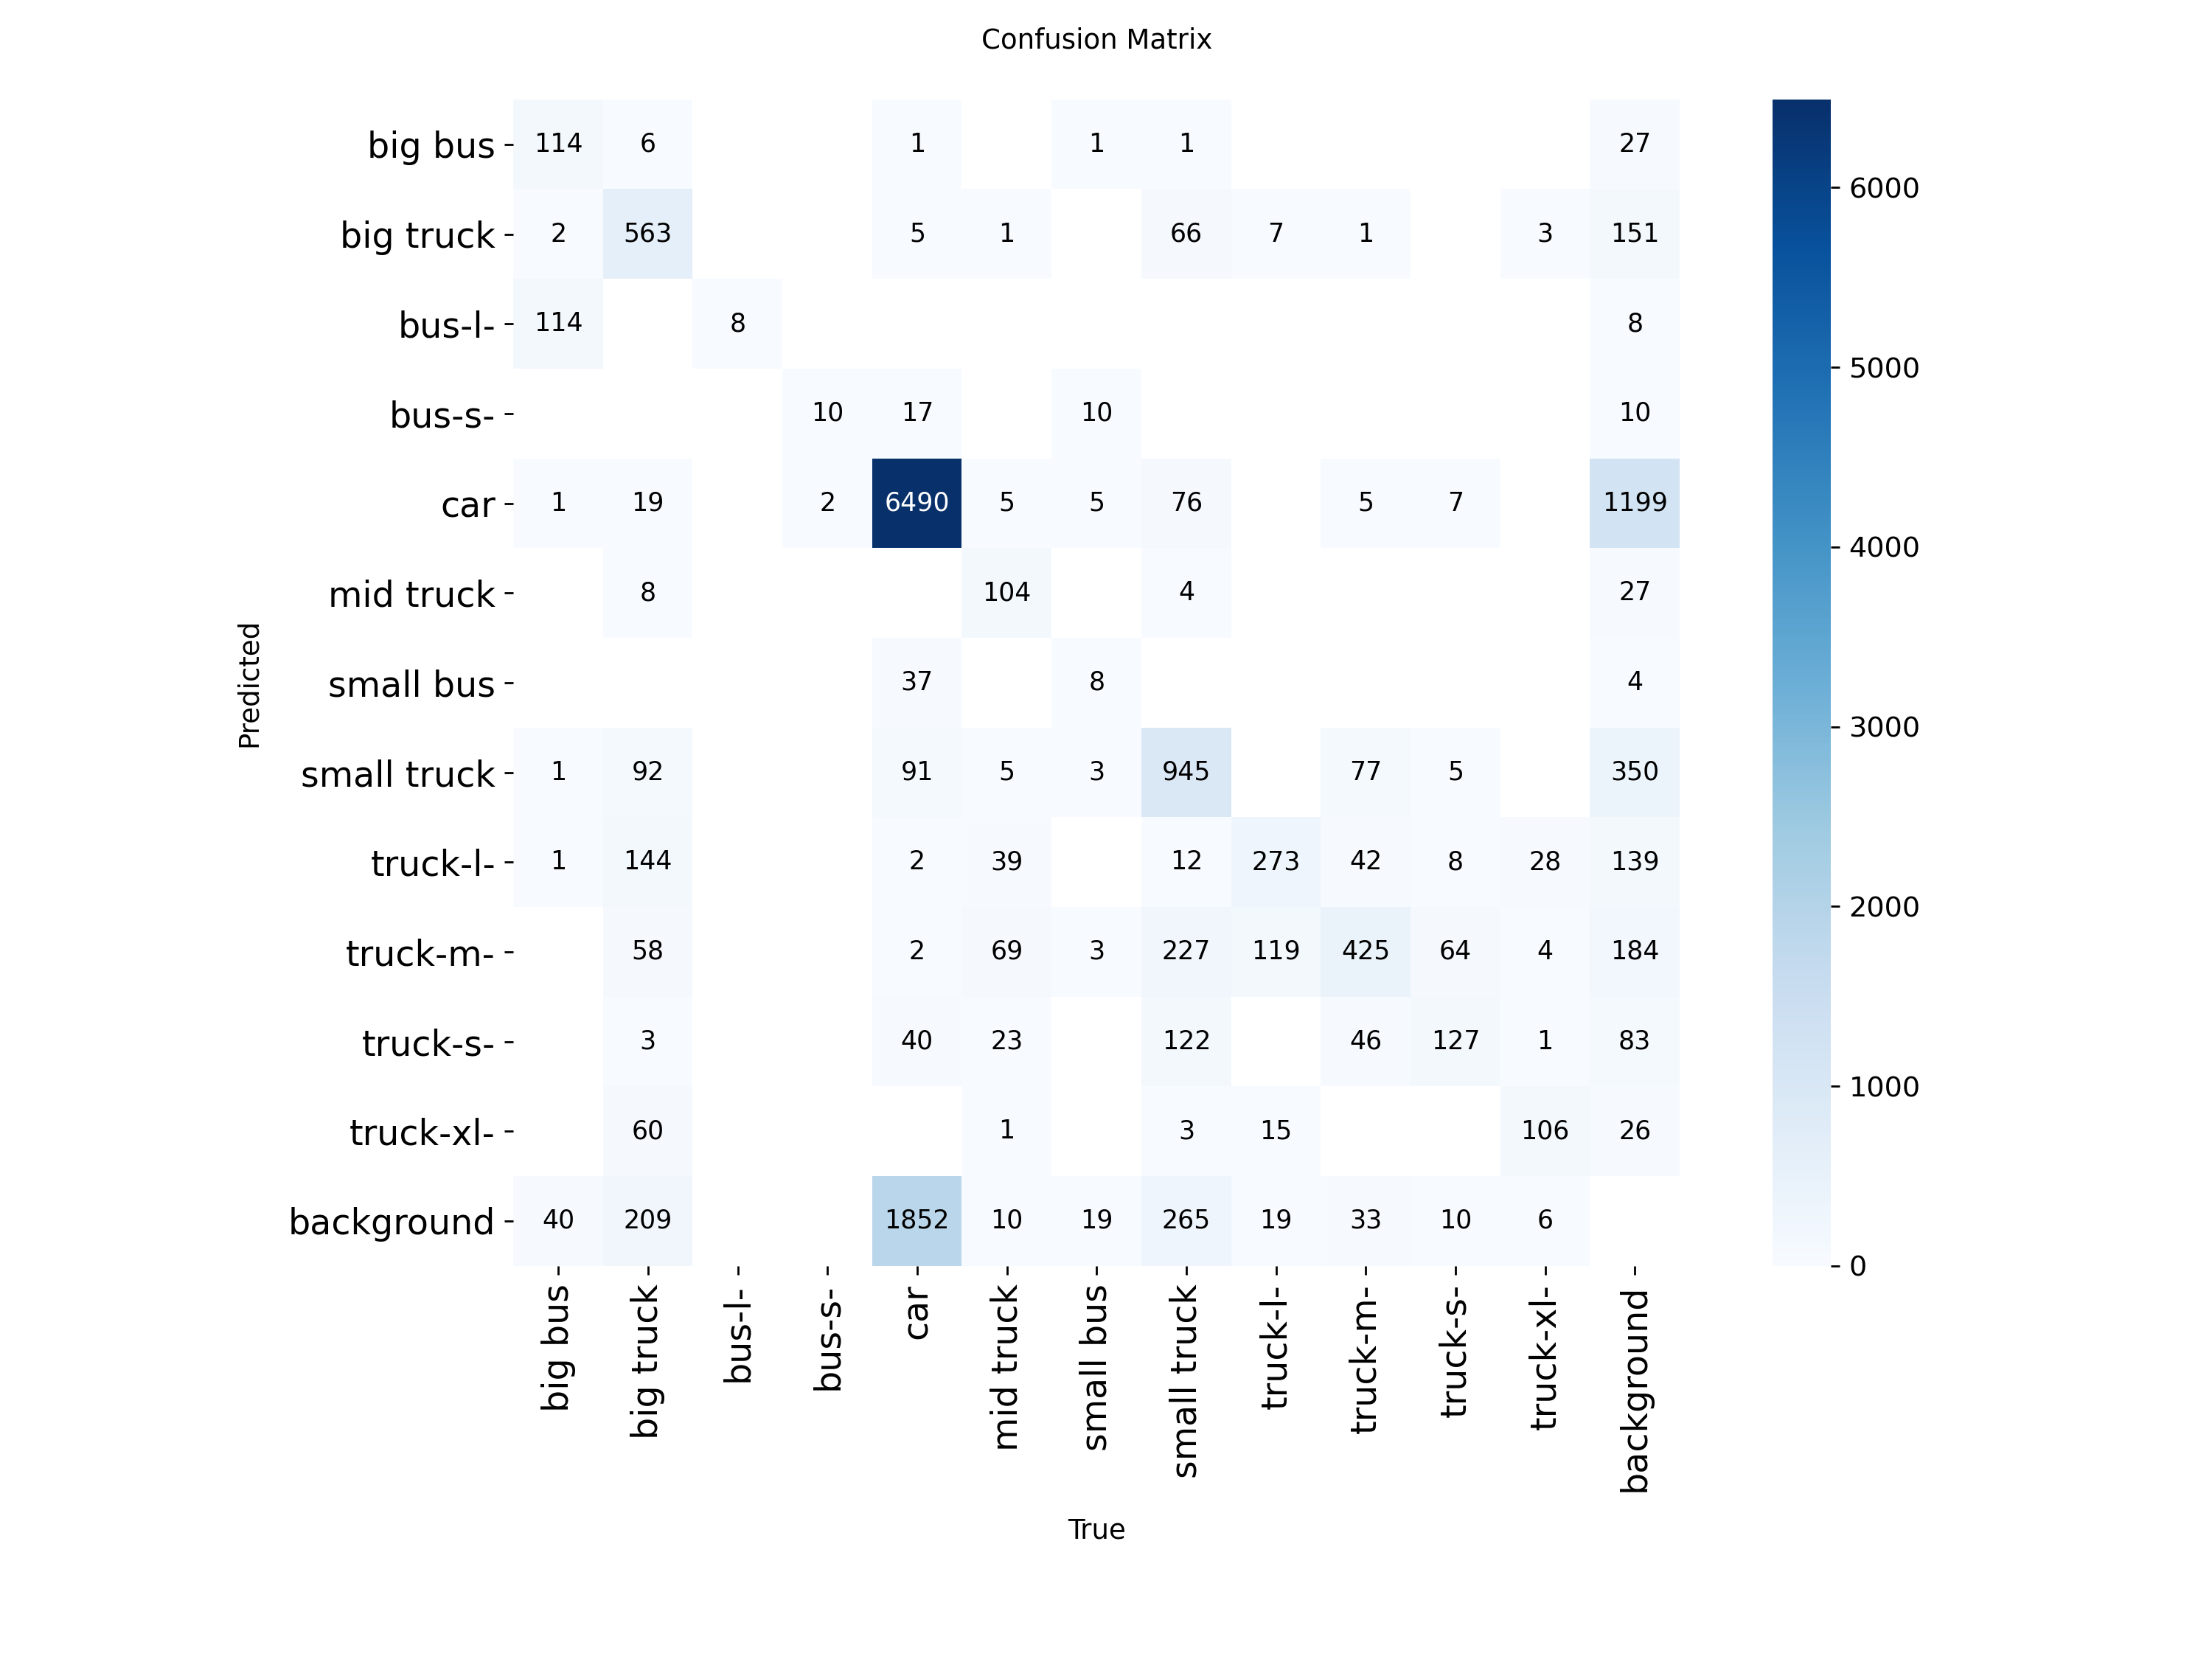


===== confusion_matrix_normalized.png =====


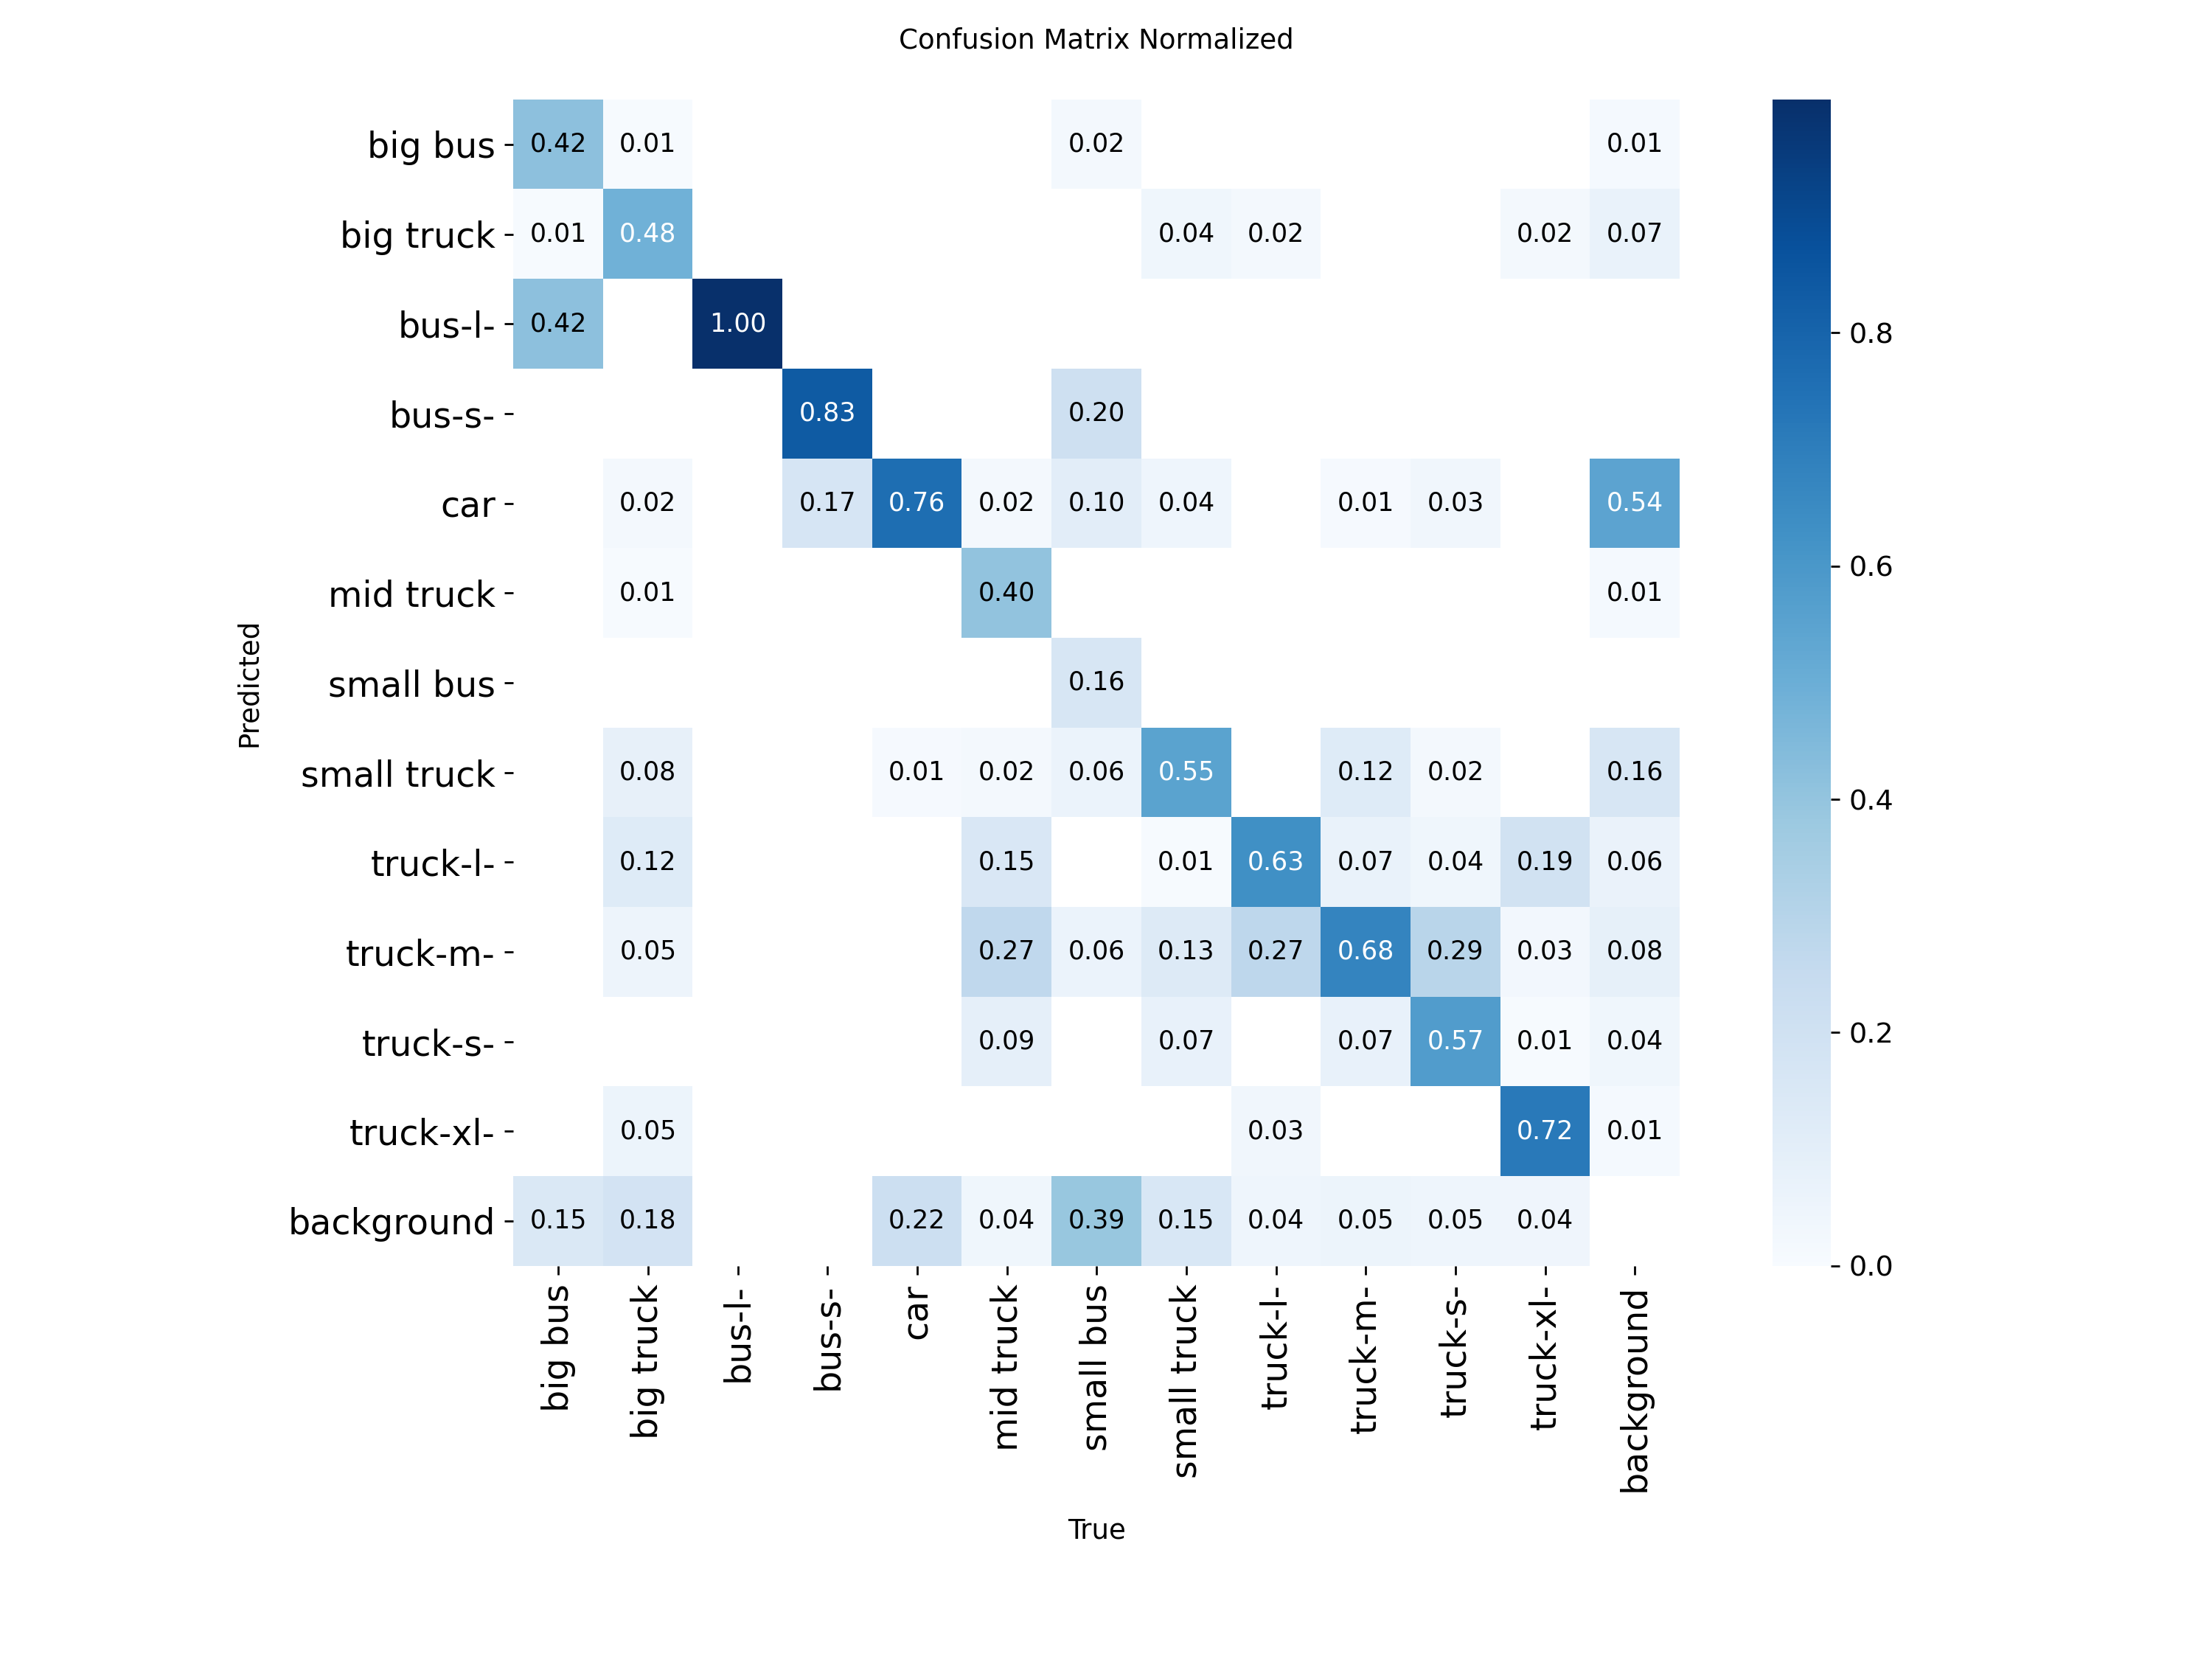


===== BoxPR_curve.png =====


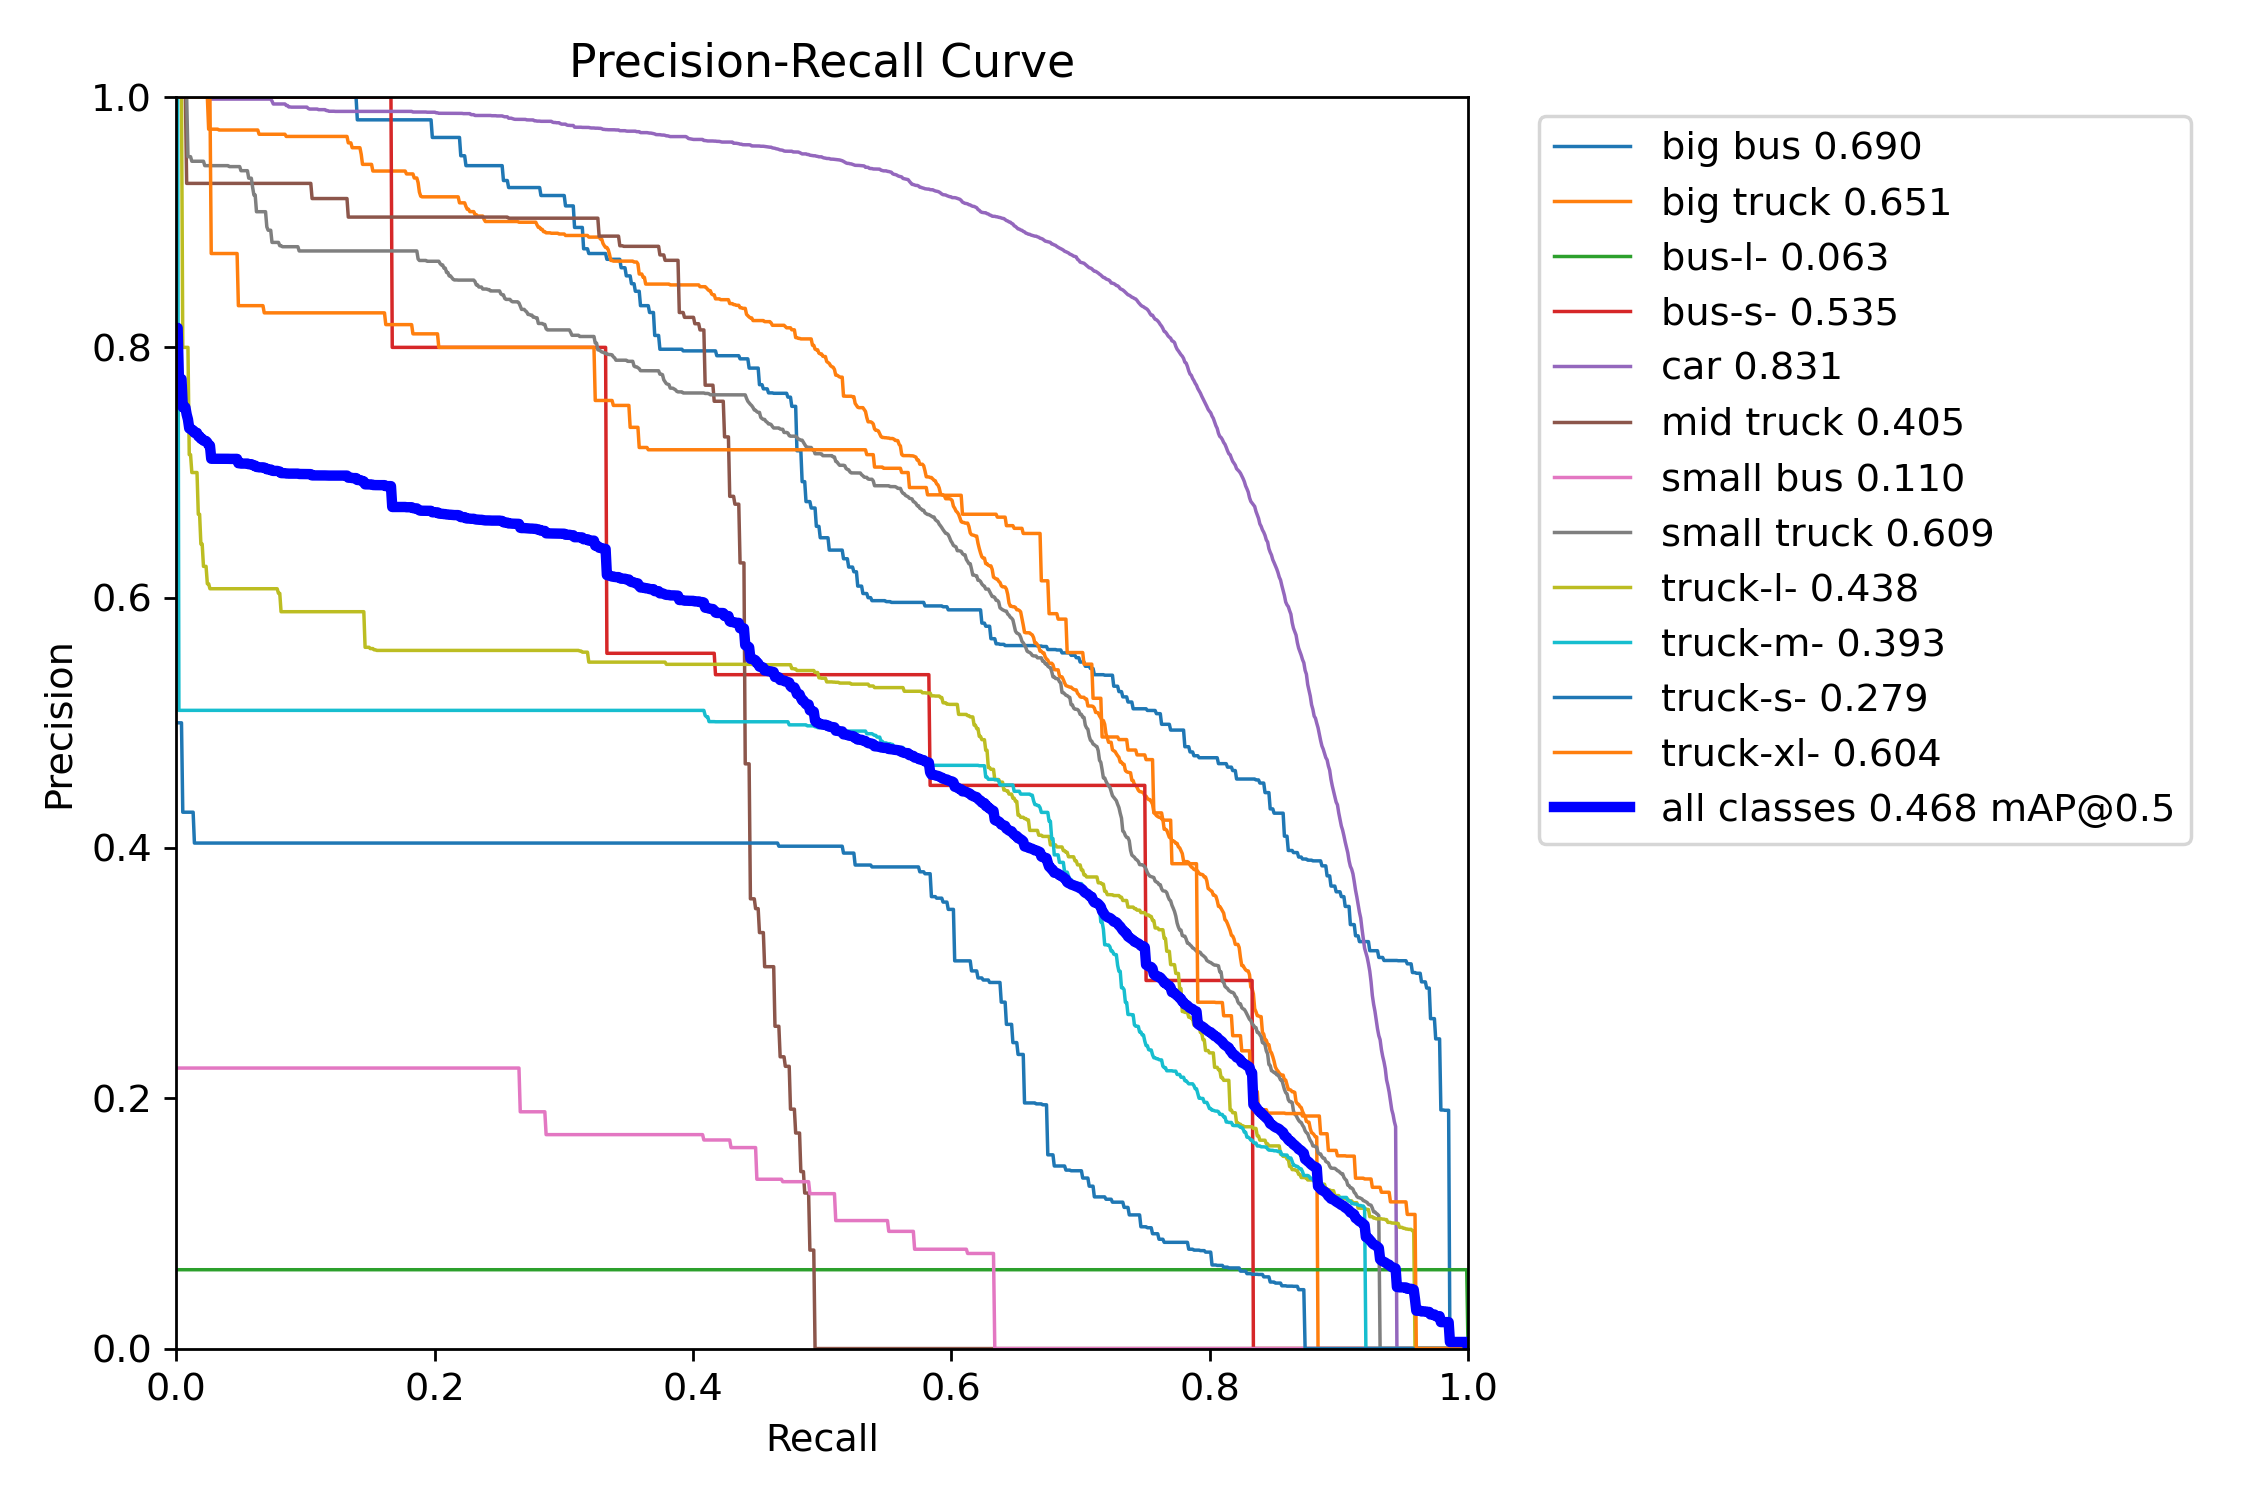


===== BoxF1_curve.png =====


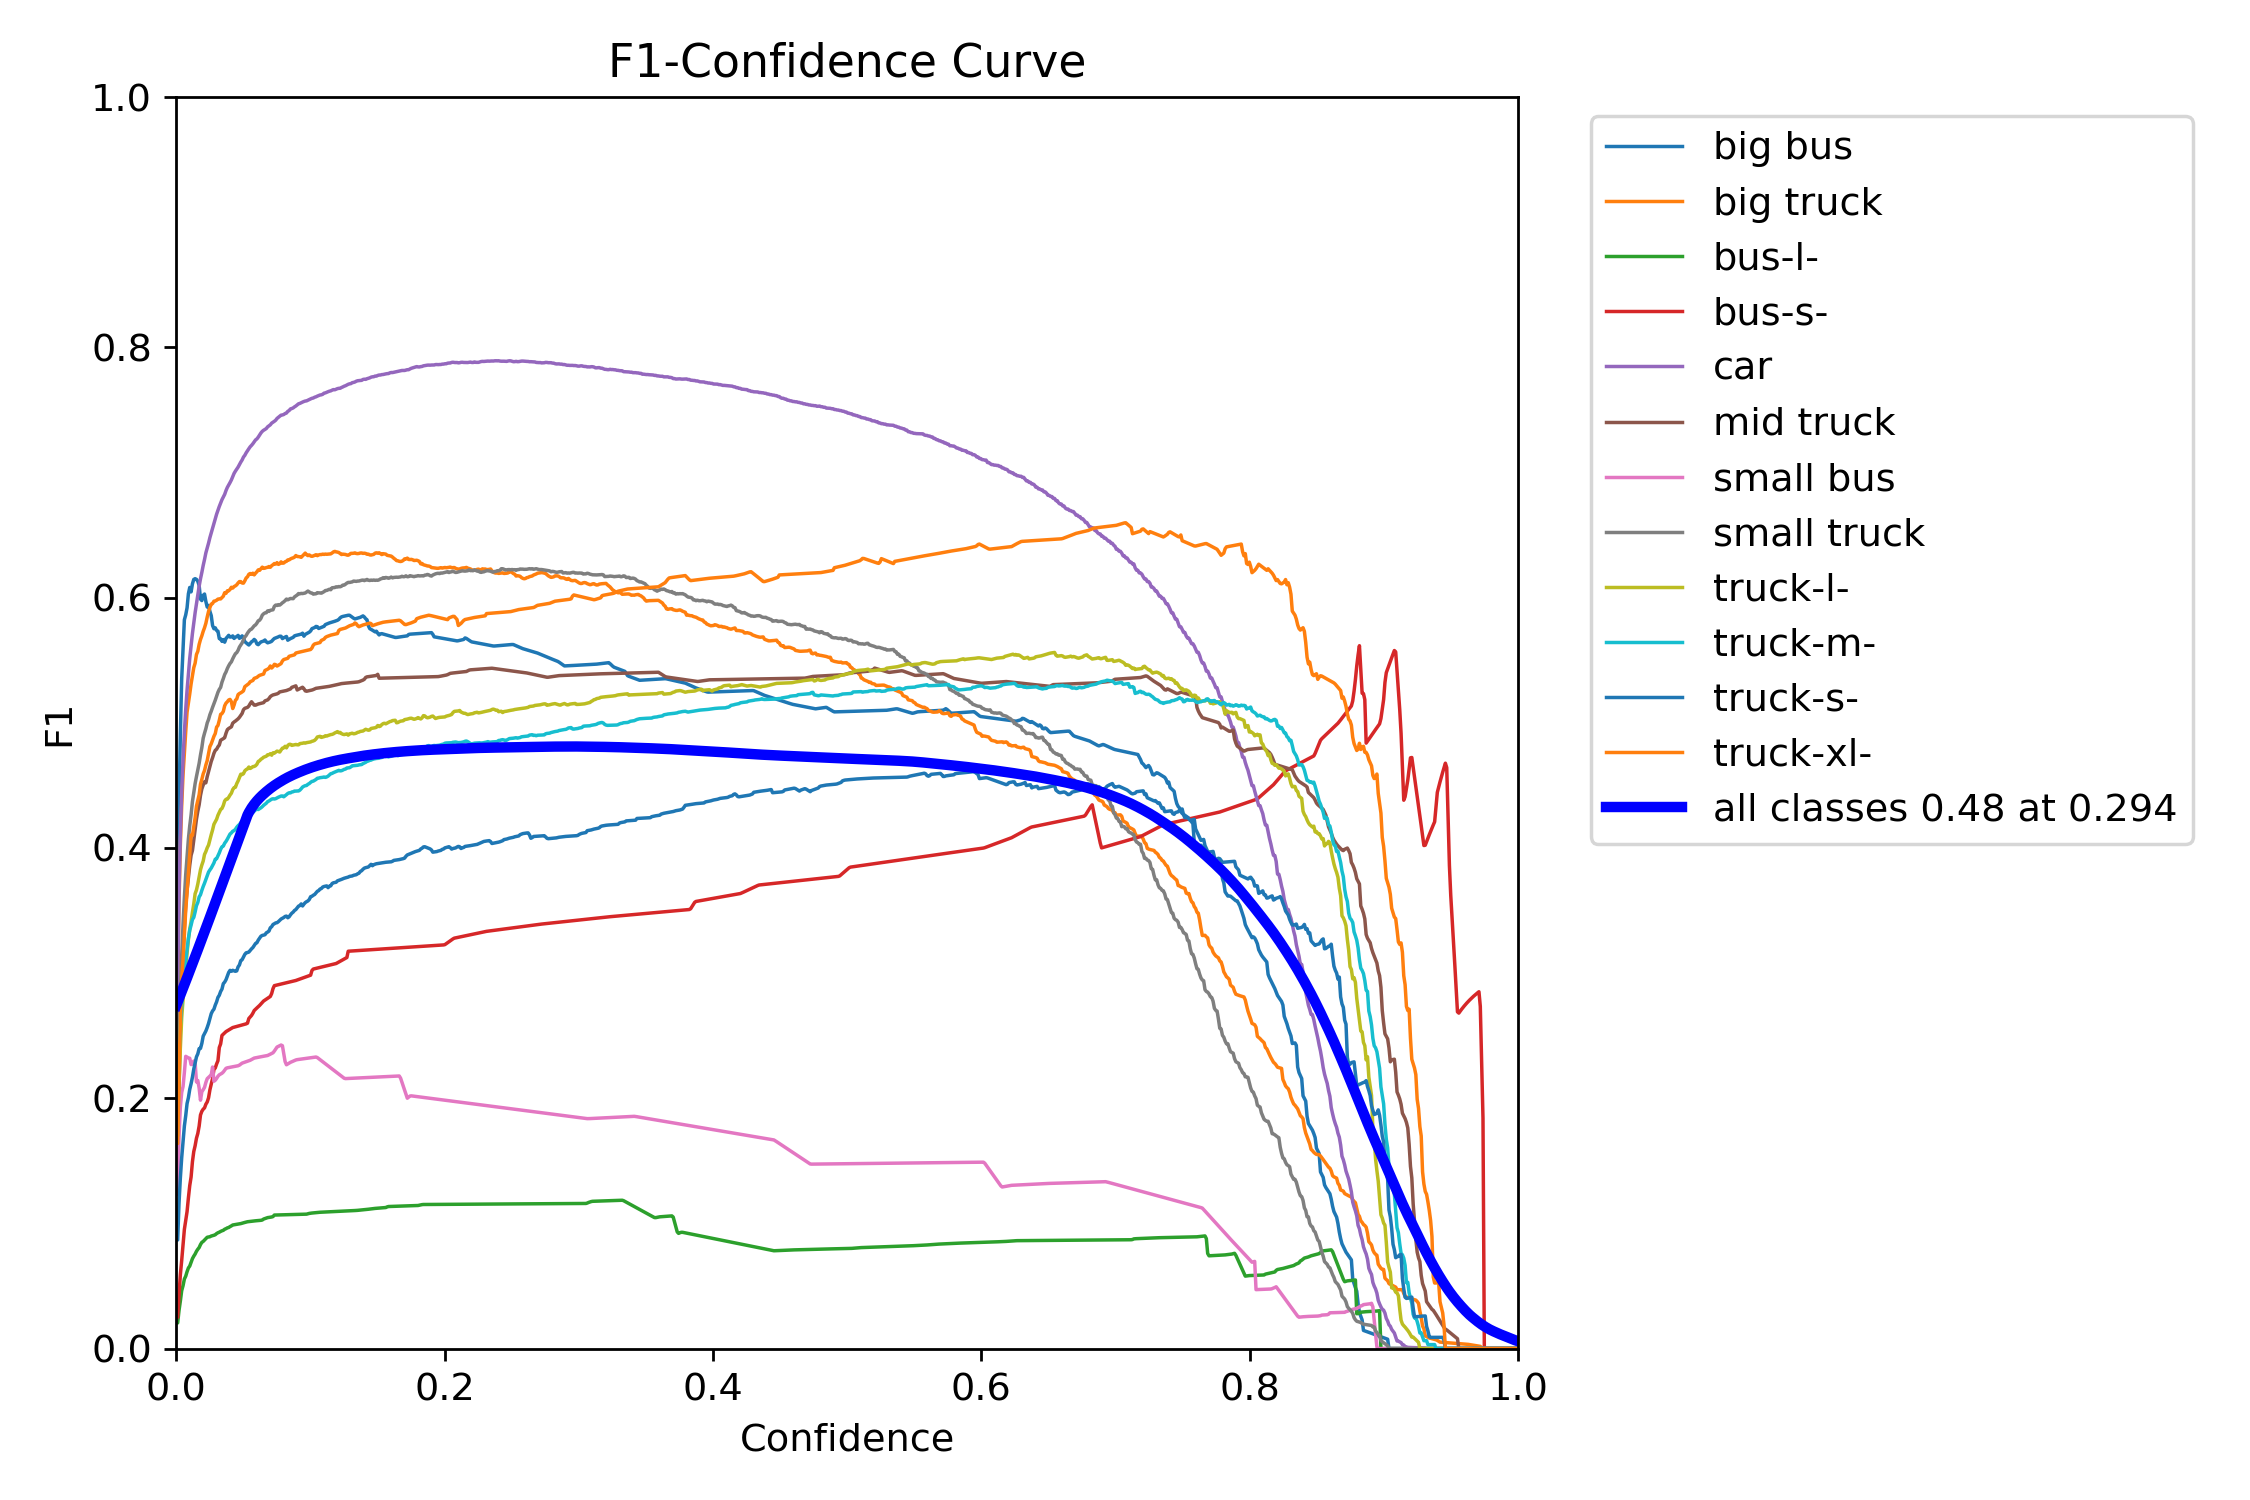

In [ ]:
from IPython.display import Image, display
import os

RESULT_DIR = f"{DRIVE_DIR}/train_50e"

evaluation_images = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png"
]

for img in evaluation_images:
    path = os.path.join(RESULT_DIR, img)

    print(f"\n===== {img} =====")
    display(Image(filename=path, width=900))

## Inference with Custom Model

In [ ]:
best_model = YOLO(f"{RESULT_DIR}/weights/best.pt")

best_model.predict(
    source=f"{dataset.location}/test/images",
    conf=0.25,
    save=True,
    project=DRIVE_DIR,
    name="predict",
    exist_ok=True
)



image 1/458 /content/datasets/vehicles-2/test/images/adit_mp4-1002_jpg.rf.5e4018e963af1251b3f7e6fd487c479e.jpg: 192x256 1 big truck, 12 cars, 1 mid truck, 1 truck-m-, 7.9ms
image 2/458 /content/datasets/vehicles-2/test/images/adit_mp4-1008_jpg.rf.e20ac34ac20c029e179d9c8bee45a078.jpg: 192x256 3 big trucks, 11 cars, 8.5ms
image 3/458 /content/datasets/vehicles-2/test/images/adit_mp4-1022_jpg.rf.8ec648b3f53103ded740458e94ae21f5.jpg: 192x256 1 big truck, 14 cars, 1 small truck, 8.7ms
image 4/458 /content/datasets/vehicles-2/test/images/adit_mp4-1028_jpg.rf.d9e26a9972e7a6815a2dff1bf35aca60.jpg: 192x256 2 big trucks, 13 cars, 1 small truck, 8.5ms
image 5/458 /content/datasets/vehicles-2/test/images/adit_mp4-1035_jpg.rf.d42b43d55c46df6098b9bd71317b740d.jpg: 192x256 3 big trucks, 15 cars, 1 small truck, 9.5ms
image 6/458 /content/datasets/vehicles-2/test/images/adit_mp4-1049_jpg.rf.ddd000b665e067666e7ae5095494e47d.jpg: 192x256 2 big trucks, 11 cars, 1 mid truck, 1 small truck, 8.7ms
image 7/4

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'big bus', 1: 'big truck', 2: 'bus-l-', 3: 'bus-s-', 4: 'car', 5: 'mid truck', 6: 'small bus', 7: 'small truck', 8: 'truck-l-', 9: 'truck-m-', 10: 'truck-s-', 11: 'truck-xl-'}
 obb: None
 orig_img: array([[[ 0,  0,  0],
         [ 6,  6,  6],
         [ 7,  7,  7],
         ...,
         [ 0,  0,  0],
         [ 0,  0,  0],
         [ 0,  0,  0]],
 
        [[ 9,  9,  9],
         [ 1,  1,  1],
         [ 7,  7,  7],
         ...,
         [ 0,  0,  0],
         [ 0,  0,  0],
         [ 0,  0,  0]],
 
        [[ 1,  1,  1],
         [ 6,  6,  6],
         [ 3,  3,  3],
         ...,
         [ 0,  0,  0],
         [ 0,  0,  0],
         [ 0,  0,  0]],
 
        ...,
 
        [[80, 82, 83],
         [80, 82, 83],
         [80, 82, 83],
         ...,
         [61, 69, 69],
         [61, 69, 69],
         [61, 69, 69]],
 
   

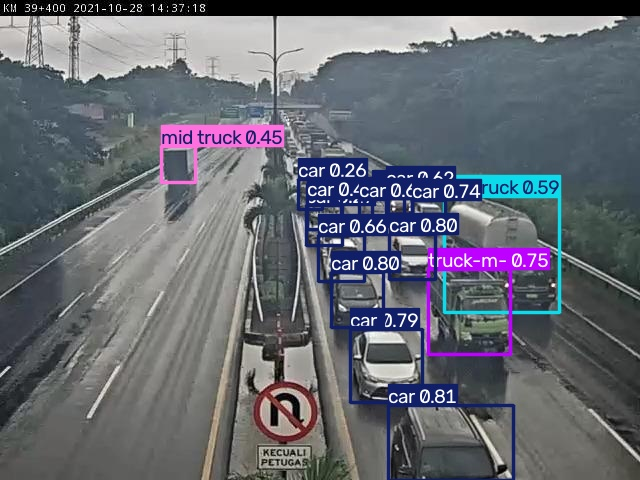

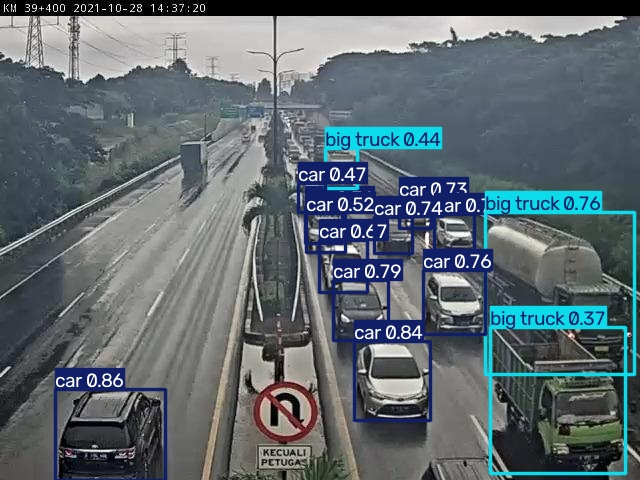

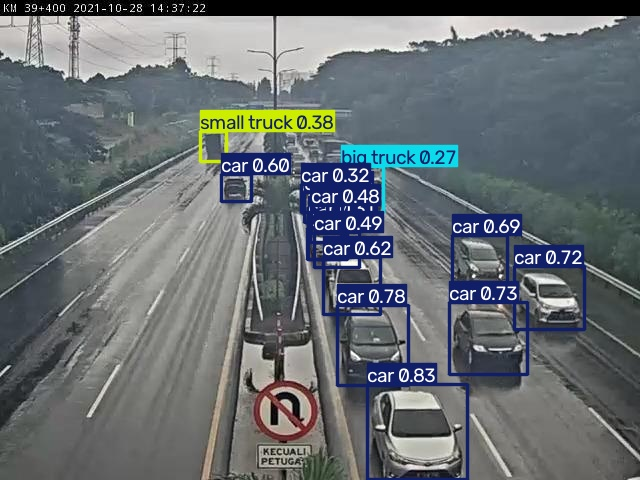

In [ ]:
import glob
from IPython.display import Image, display

for image_path in glob.glob(f"{DRIVE_DIR}/predict/*.jpg")[:3]:
    display(Image(filename=image_path, height=600))
    print()